# A/B-тест нового интерфейса интернет-магазина

Проверка влияния обновлённого интерфейса на конверсию в покупку и оценка достаточности эффекта для продуктового решения.


# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



Определить есть ли статистически значимый рост конверсии в покупку среди пользователей новой версии сайта и достигается ли нужный масштаб эффективности. Для этого мы планируем:
1. Оценить корректность проведения теста
2. Провести оценку результатов AB-теста

## 2. Загрузите данные, оцените их целостность.


In [ ]:
participants = pd.read_csv(
    "https://code.s3.yandex.net/datasets/ab_test_participants.csv"
)
events = pd.read_csv(
    "https://code.s3.yandex.net/datasets/ab_test_events.zip",
    parse_dates=["event_dt"],
    low_memory=False,
)

In [17]:
# Выведем первые строчки датафрейма с участниками теста
display(participants.head())

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [18]:
# Выведем общую информацию о датафрейме с участниками теста
display(participants.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB


None

In [19]:
# Выведем первые строчки датафрейма с событиями
display(events.head())

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [20]:
# Выведем общую информацию о датафрейме c событиями
display(events.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


None

## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [21]:
# Проверим дубликаты в датафрейме
participants.duplicated().sum()

0

Полных дубликатов не найдено

In [22]:
# Проверим дубликаты в столбце user_id
participants.duplicated(subset=["user_id"]).sum()

# Сохраняем id дублирующихся пользователей
user_check = participants[participants.duplicated(subset=["user_id"])][
    "user_id"
].to_list()
participants[participants["user_id"].isin(user_check)].sort_values(
    by=["user_id", "ab_test"]
).head(10)

,user_id,group,ab_test,device
2,001064FEAAB631A1,A,interface_eu_test,Android
1,001064FEAAB631A1,B,recommender_system_test,Android
10,00341D8401F0F665,B,interface_eu_test,iPhone
9,00341D8401F0F665,A,recommender_system_test,iPhone
25,0082295A41A867B5,A,interface_eu_test,iPhone
26,0082295A41A867B5,A,recommender_system_test,iPhone
42,00E68F103C66C1F7,A,interface_eu_test,PC
41,00E68F103C66C1F7,A,recommender_system_test,PC
45,00EFA157F7B6E1C4,B,interface_eu_test,Android
46,00EFA157F7B6E1C4,A,recommender_system_test,Android


Видим, что значения user_id дублируются из-за поля ab_test. Так как мы берем в анализ только результаты теста interface_eu_test ситуация с дублями не мешает дальнейшему анализу. Подготовим отфильтрованный датафрейм без данных теста recommender_system_test


In [23]:
# Проверим пересечение пользователей в двух тестах
a_group = participants[participants["ab_test"] == "interface_eu_test"]["user_id"]
b_group = participants[participants["ab_test"] == "recommender_system_test"]["user_id"]

intersection_test = list(set(a_group) & set(b_group))
length = len(intersection_test)
print(f"В тесте interface_eu_test {a_group.nunique()} пользователей")
print(f"В тесте recommender_system_test {b_group.nunique()} пользователей")
print(f"В двух тестах найдено {length} пересекающихся пользователей")
# Создадим дф только с пользователями из теста interface_eu_test
interface_users = participants[participants["ab_test"] == "interface_eu_test"]
# Исключим из теста interface_eu_test пересечения со вторым тестом
participants = interface_users[~interface_users["user_id"].isin(intersection_test)]

# Выведем итоговое количество пользователей
print(
    f'Количество пользователей в тесте interface_eu_test после очистки {participants["user_id"].nunique()}'
)

В тесте interface_eu_test 10850 пользователей
В тесте recommender_system_test 3675 пользователей
В двух тестах найдено 887 пересекающихся пользователей
Количество пользователей в тесте interface_eu_test после очистки 9963


In [24]:
# Посмотрим на распределение между группами A и B в абсолютах
print(participants[participants["group"] == "A"]["user_id"].nunique())
print(participants[participants["group"] == "B"]["user_id"].nunique())

# Посмотрим на распределение между группами A и B в долях
print(
    100.0
    * participants[participants["group"] == "A"]["user_id"].nunique()
    / participants["user_id"].nunique()
)
print(
    100.0
    * participants[participants["group"] == "B"]["user_id"].nunique()
    / participants["user_id"].nunique()
)

4952
5011
49.70390444645187
50.29609555354813


Количество пользователей больше в тестовой группе, но разница не превышает 1%. Поэтому расхождением можно пренебречь

In [25]:
# Проверим пересечение пользователей
a_group = participants[participants["group"] == "A"]["user_id"]
b_group = participants[participants["group"] == "B"]["user_id"]

intersection = list(set(a_group) & set(b_group))
print(intersection)

[]


Группы уникальны по пользователям

3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [26]:
# Предварительно определим полные дубликаты и очистим датафрейм от них при наличии
print(events.duplicated().sum())
events = events.drop_duplicates().reset_index(drop=True)
print(events.duplicated().sum())

36318
0


In [ ]:
# Создадим список с user_id из таблицы participants
user_ids_ab = participants["user_id"].to_list()
# Создадим новый датафрейм на основе таблицы events, учитывая список с user_id
events_ab = events.merge(participants, on="user_id", how="inner")

- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [28]:
# Создаем таблицу с пользователями и датой их регистрации
users_reg = events_ab[["user_id", "event_dt"]][
    events_ab["event_name"] == "registration"
]
users_reg = users_reg.rename(columns={"event_dt": "reg_dt"})

# Объединям основную таблицу и таблицу регистрации
events_ab = events_ab.merge(users_reg, on="user_id", how="inner")

# Cчитаем разницу между событием и датой регистрации
events_ab["diff"] = events_ab["event_dt"] - events_ab["reg_dt"]
# Оставляем строки с событиями которые произошли не позднее 7 дней после регистрации
events_ab = events_ab[events_ab["diff"] <= pd.Timedelta(days=7)]
events_ab.head(5)

,user_id,event_dt,event_name,details,group,ab_test,device,reg_dt,diff
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,A,interface_eu_test,iPhone,2020-12-06 14:10:01,0 days 00:00:00
1,5F506CEBEDC05D30,2020-12-07 01:25:14,login,NaN,A,interface_eu_test,iPhone,2020-12-06 14:10:01,0 days 11:15:13
2,5F506CEBEDC05D30,2020-12-07 01:25:47,login,NaN,A,interface_eu_test,iPhone,2020-12-06 14:10:01,0 days 11:15:46
3,5F506CEBEDC05D30,2020-12-09 12:40:49,login,NaN,A,interface_eu_test,iPhone,2020-12-06 14:10:01,2 days 22:30:48
4,5F506CEBEDC05D30,2020-12-09 12:40:49,product_page,NaN,A,interface_eu_test,iPhone,2020-12-06 14:10:01,2 days 22:30:48


Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [29]:
# Посмотрим на распределение между группами A и B в абсолютах
users = events_ab.groupby("group")["user_id"].nunique()
if users["A"] > 3692 or users["B"] > 3692:
    print(
        f'По расчету в калькуляторе Эвана Миллера размер выборки для каждой группы составляет 3 692 пользователя. В нашей выборке в группу А попали {users["A"]} пользователя, в группу B попали {users["B"]} пользователя. Выборка достаточна'
    )
else:
    print(
        f'По расчету в калькуляторе Эвана Миллера размер выборки для каждой группы составляет 3 692 пользователя. В нашей выборке в группу А попали {users["A"]} пользователя. В нашей выборке в группу B попали {users["B"]} пользователя. Выборка недостаточна'
    )

По расчету в калькуляторе Эвана Миллера размер выборки для каждой группы составляет 3 692 пользователя. В нашей выборке в группу А попали 4952 пользователя, в группу B попали 5011 пользователя. Выборка достаточна


- рассчитайте для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

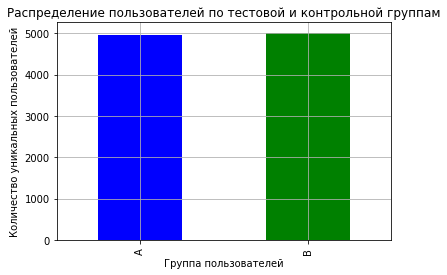

В нашей выборке в группу А попали 4952 пользователя, в группу B попали 5011 пользователя


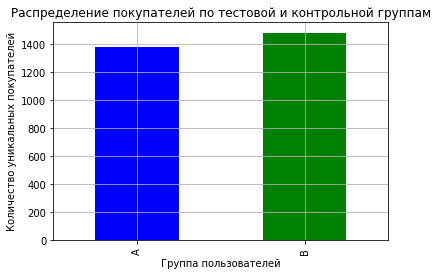

В нашей выборке в группу А попали 1377 покупателя, в группу B попали 1480 покупателя


In [30]:
# Визуализируем количество пользователей
colors = ["blue", "green"]
users.plot(kind="bar", color=colors)
plt.title("Распределение пользователей по тестовой и контрольной группам")
plt.xlabel("Группа пользователей")
plt.ylabel("Количество уникальных пользователей")
plt.grid(True)
plt.show()
print(
    f'В нашей выборке в группу А попали {users["A"]} пользователя, в группу B попали {users["B"]} пользователя'
)


# Рассчитаем и визуализируем количество покупателей
buyers = (
    events_ab[events_ab["event_name"] == "purchase"]
    .groupby("group")["user_id"]
    .nunique()
)
colors = ["blue", "green"]
buyers.plot(kind="bar", color=colors)
plt.title("Распределение покупателей по тестовой и контрольной группам")
plt.xlabel("Группа пользователей")
plt.ylabel("Количество уникальных покупателей")
plt.grid(True)
plt.show()
print(
    f'В нашей выборке в группу А попали {buyers["A"]} покупателя, в группу B попали {buyers["B"]} покупателя'
)


# Рассчитаем и визуализируем количество покупателей по устройствам
buyers_dev = (
    events_ab[events_ab["event_name"] == "purchase"]
    .groupby(["group", "device"])["user_id"]
    .nunique()
)

- сделайте предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

In [31]:
# Посчитаем конверсию в покупку по группам
cr_control = 100.0 * buyers["A"] / users["A"]
cr_test = 100.0 * buyers["B"] / users["B"]
print(
    f"Относительное изменение конверсии составило +{round(cr_test - cr_control / cr_control,2)}% "
)
print(
    f"Абсолютное изменение конверсии составило +{round(cr_test - cr_control,2)} п.п. "
)
print(
    f"Конверсия в покупку у контрольной группы составила {round(cr_control,2)}%. Конверсия в тестовой группе составила {round(cr_test,2)}%"
)

Относительное изменение конверсии составило +28.54% 
Абсолютное изменение конверсии составило +1.73 п.п. 
Конверсия в покупку у контрольной группы составила 27.81%. Конверсия в тестовой группе составила 29.54%


Конверсия в покупку в тестовой группе выше на 28,5% или на 1.73 п.п

## 4. Проведите оценку результатов A/B-тестирования:

- Проверьте изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

Н0: Новая версия сайта не влияет на рост конверсии в покупку зарегистрированных пользователей 
Н1: Новая версия сайта влияет на конверсию в покупку зарегистрированных пользователей

In [32]:
## размеры выборок A и B
n_a, n_b = users["A"], users["B"]
m_a = buyers["A"]  # количество успехов (регистраций) в группе A
m_b = buyers["B"]  # количество успехов (регистраций) в группе B

p_a, p_b = m_a / n_a, m_b / n_b  # рассчитываем доли успехов для каждой группы: A и B

print(f"n_a={n_a}, n_b={n_b}")

print(f"m_a={m_a}, m_b={m_b}")

print(f"p_a={p_a}, p_b={p_b}")

if (
    (p_a * n_a > 10)
    and ((1 - p_a) * n_a > 10)
    and (p_b * n_b > 10)
    and ((1 - p_b) * n_b > 10)
):
    print("Предпосылка о достаточном количестве данных выполняется!")
else:
    print("Предпосылка о достаточном количестве данных НЕ выполняется!")

n_a=4952, n_b=5011
m_a=1377, m_b=1480
p_a=0.27806946688206785, p_b=0.29535022949511075
Предпосылка о достаточном количестве данных выполняется!


In [33]:
# Так как метрика долевая применим z-test пропорций
from statsmodels.stats.proportion import proportions_ztest

alpha = 0.05

stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b], [n_a, n_b], alternative="smaller"
)
p_value_ztest

if p_value_ztest > alpha:
    print(f"pvalue={p_value_ztest} > {alpha}")
    print("Нулевая гипотеза находит подтверждение!")
else:
    print(f"pvalue={p_value_ztest} < {alpha}")
    print("Нулевая гипотеза не находит подтверждения!")

pvalue=0.028262547212292124 < 0.05
Нулевая гипотеза не находит подтверждения!


- Опишите выводы по проведённой оценке результатов A/B-тестирования. Что можно сказать про результаты A/B-тестирования? Был ли достигнут ожидаемый эффект в изменении конверсии?

Параметры теста: уровень значимости 0.05%. Мощность теста - 80%. Размер выборки 9963 пользователей.

Результаты теста показывают, что изменения в новой версии сайта (группа B) действительно повлияли на поведение пользователей. Разница в конверсиях не является случайной.
При этом, конверсия в тестовой группе выше на 1,73 п.п, что меньше ожидаемого эффекта (> 3 п.п) от внедрения новой версии сайта. С текущими результатами переводить всю аудиторию может быть рискованно, т.к эффект от изменений может быть ниже желаемого.

Рекомендуем провести дополнительное исследование конверсии по этапам воронки, чтобы определить на каком этапе происходят основные потери пользователей. Например, при оформлении покупки. После чего внести корректировки на данном этапе и провести повторный тест.   

В качестве альтернативы можно проверить конверсию по устройствам. По расчетам видно, что рост конверсии на устройствах Mac выше ожидаемого эффекта (+ 4.9 п.п). В таком случае можно пересчитать тест для Mac и проверить насколько рост конверсии значимый. Если разница не будет случайной, то новую версию на старте можне выкатить на всех пользователей Mac, а для остальных устройств продолжить тестирование или оставить старую версию.

In [34]:
# Рассчитаем конверсию по устройствам
users_dev = events_ab.groupby(["group", "device"])["user_id"].nunique()
buyers_dev = (
    events_ab[events_ab["event_name"] == "purchase"]
    .groupby(["group", "device"])["user_id"]
    .nunique()
)
conversion_by_device = 100.0 * buyers_dev / users_dev
display(conversion_by_device)

group  device 
A      Android    28.180212
       Mac        26.019417
       PC         27.636958
       iPhone     28.105263
B      Android    28.629396
       Mac        30.919765
       PC         30.184332
       iPhone     30.000000
Name: user_id, dtype: float64